# 阴阳谜题：用整数编号来表达同色格的连通性

## 本章的内容

阴阳是把盘面涂成黑白的谜题，由于没有 `add_circuit()` 那样的现成约束，模型只能自己搭建。

- 每格带两个变量，即颜色与遍历顺序
- 相邻的同色格之间，必定按其中一个方向的边相连
- 编号递增的方向连边，同色格因而全部连通
- 不造出同色的 2×2 方块，即不让四格同色

四条里，前三条合起来实现连通，最后一条禁止同色的方块。

## 规则

在长方形的网格中，有些格一开始就放着黑或白的棋子，其余格涂色，使下面三条成立。

1. 所有黑格通过上下左右的连接成为一个整体
2. 所有白格通过上下左右的连接成为一个整体
3. 不能出现同色的 2×2 方块

规则的三条里，前两条说的是连通，第三条说的是形状。

中心带点的格就是题目给出的棋子。

![](images/yinyang.png)

`````{admonition} 阴阳谜题的网站
:class: tip
https://www.puzzle-yin-yang.com/

用 `helper.puzzle.extract_yinyan()` 可以取得这个网站上的谜题盘面。打开浏览器的开发者工具，把表示盘面的 `<div>` 标签的代码复制下来，交给这个函数执行，盘面就会以数组的形式取得。
`````

## 盘面

`1` 是白棋子，`2` 是黑棋子，`0` 是空格。

In [1]:
import numpy as np

puzzle = np.loadtxt('data/yinyang01.txt', dtype=np.uint8)
print(puzzle)

[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 0 0]
 [0 2 0 0 0 0]
 [1 0 2 1 0 0]]


In [2]:
from ortools.sat.python import cp_model
import numpy as np
from collections import defaultdict

## 思路

每格带下面两个变量。

| 变量 | 含义 |
|---|---|
| `colors[r, c]`，布尔 | 假为白，真为黑 |
| `steps[r, c]`，整数 | 在同色之中第几个被遍历 |

颜色决定哪些格要连通，编号决定用哪一组边把它们连起来。

在相邻格之间还要准备有向边，其中 `edge12` 表示格 1 到格 2，`edge21` 表示反方向。约束共有七条。

1. 两个方向不能同时选，即 `edge12` 与 `edge21` 不能同时为真
2. 有边则同色，即 `edge12` 为真则 `color1 == color2`
3. 同色则必有边，即 `color1 == color2` 时 `edge12` 与 `edge21` 中必有一个为真
4. 方向与编号，即 `edge12` 为真则 `step1 < step2`
5. 每格的入口只有一个，除起点之外，进入的边恰好一条
6. 起点没有入口，白与黑的起点，进入的边都是 0 条
7. 禁止 2×2，即四格不能同色

把第 2 条与第 3 条合起来，同色的格之间必定有边；再由第 4 条与第 5 条，从起点沿编号递增的方向走，可以到达每一格，也就是同色格成为一个整体，这正是连通的含义。编号在这里不是装饰，而是把连通换成了沿边递增可达。

起点在白与黑中各选一个即可，这相当于每种颜色各造一棵树。

In [3]:
def solve_yinyang(puzzle):
    """求解 Yin-Yang，返回（颜色、编号、选中的边）"""
    model = cp_model.CpModel()
    h, w = puzzle.shape
    edges = []

    colors = {}
    steps = {}

    for (r, c), v in np.ndenumerate(puzzle):
        colors[r, c] = model.new_bool_var(f'color_{r}_{c}')
        steps[r, c] = model.new_int_var(0, h * w, f'step_{r}_{c}')
        if c + 1 < w:
            edges.extend([(r, c, r, c + 1), (r, c + 1, r, c)])
        if r + 1 < h:
            edges.extend([(r, c, r + 1, c), (r + 1, c, r, c)])

    edge_variables = {e: model.new_bool_var(f'edge_{e}') for e in edges}

    out_edges = defaultdict(list)
    in_edges = defaultdict(list)
    for e in edges:
        out_edges[e[:2]].append(e)
        in_edges[e[2:]].append(e)

    # 起点（白、黑各自第一颗棋子）
    whites = np.where(puzzle == 1)
    blacks = np.where(puzzle == 2)
    start_locs = [(whites[0][0], whites[1][0]), (blacks[0][0], blacks[1][0])]

    for (r1, c1, r2, c2) in edges:
        n1, n2 = (r1, c1), (r2, c2)
        if n1 > n2:
            continue        # 每对只处理一次

        cell1, cell2 = colors[n1], colors[n2]
        step1, step2 = steps[n1], steps[n2]
        edge12, edge21 = edge_variables[r1, c1, r2, c2], edge_variables[r2, c2, r1, c1]

        # 1. 不同时选两个方向
        model.add_bool_or(~edge12, ~edge21)
        # 2. 有边就同色（4 种组合用 CNF 写）
        model.add_bool_or(~cell1, cell2, ~edge12)
        model.add_bool_or(cell1, ~cell2, ~edge12)
        model.add_bool_or(~cell1, cell2, ~edge21)
        model.add_bool_or(cell1, ~cell2, ~edge21)
        # 3. 同色时，必有一个方向的边
        model.add_bool_or(cell1, cell2, edge12, edge21)
        model.add_bool_or(~cell1, ~cell2, edge12, edge21)
        # 4. 沿边的方向编号递增
        model.add(step1 < step2).only_enforce_if(edge12)
        model.add(step1 > step2).only_enforce_if(edge21)

    for (r, c), v in np.ndenumerate(puzzle):
        in_vars = [edge_variables[e] for e in in_edges[r, c]]
        out_vars = [edge_variables[e] for e in out_edges[r, c]]

        if (r, c) not in start_locs:
            # 5. 起点以外，入边恰好 1 条
            model.add(sum(in_vars) == 1)
            model.add(steps[r, c] > 0)
        else:
            # 6. 起点没有入边，出边 1 条以上
            model.add(sum(in_vars) == 0)
            model.add(sum(out_vars) > 0)
            model.add(steps[r, c] == 0)

        # 固定棋子的颜色
        if v == 1:
            model.add_bool_and(~colors[r, c])
        elif v == 2:
            model.add_bool_and(colors[r, c])

    # 7. 不允许同色的 2×2
    for r in range(h - 1):
        for c in range(w - 1):
            quad = [colors[r, c], colors[r + 1, c], colors[r, c + 1], colors[r + 1, c + 1]]
            model.add_bool_or(quad)                        # 全白不行
            model.add_bool_or([~v for v in quad])          # 全黑也不行

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 120
    status = solver.solve(model)
    print("status:", solver.status_name(status))

    cells = {key: solver.value(val) for key, val in colors.items()}
    numbers = {key: solver.value(val) for key, val in steps.items()}
    chosen = [key for key, val in edge_variables.items() if solver.value(val)]
    return cells, numbers, chosen

### 补充：为什么写成 CNF

也可以写成 `model.add(cell1 == cell2).only_enforce_if(edge12)`，但把比较式作为条件的形式，CP-SAT 有时难以求解，因此这里展开成“…或…”的形式，即 CNF。展开之后子句变多，但每条都只含布尔变量，求解器处理起来更直接。

- `~edge12 | ~edge21`：两个不能同时成立
- `~cell1 | cell2 | ~edge12`：`edge12` 为真则 `cell1 → cell2`
- `cell1 | ~cell2 | ~edge12`：`edge12` 为真则 `cell2 → cell1`

由后两条子句就得到“`edge12` 为真则 `cell1 == cell2`”。`edge21` 方向同理再写两条，四条蕴含子句合起来，边的方向与同色的关系就完整了。

## 绘制

涂上颜色，再把编号与边叠加上去显示。

In [4]:
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection


def plot_yinyang(puzzle, cells=None, numbers=None, edges=None, scale=0.3):
    h, w = puzzle.shape
    fig, ax = plt.subplots(figsize=(w * scale, h * scale))

    if cells is not None:
        xs, ys, colors = [], [], []
        for (y, x), v in cells.items():
            xs.append(x)
            ys.append(y)
            colors.append('white' if v == 0 else 'black')
        ax.scatter(xs, ys, s=80 * scale / 0.1, c=colors)

    if numbers:
        for (r, c), num in numbers.items():
            color = 'black' if cells[r, c] == 0 else 'white'
            ax.text(c, r, str(num), color=color, size=9)

    if edges:
        segments = []
        for r1, c1, r2, c2 in edges:
            segments.append([(c1, r1), (c2, r2)])
        ax.add_collection(LineCollection(segments, alpha=0.7))

    y, x = np.where(puzzle == 1)
    ax.scatter(x, y, s=8, edgecolor="#000000", facecolor="none")

    y, x = np.where(puzzle == 2)
    ax.scatter(x, y, s=8, edgecolor="#ffffff", facecolor="none")

    ax.set_aspect('equal')
    fig.patch.set_facecolor('#777777')
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(-0.5, h - 0.5)
    ax.invert_yaxis()
    ax.axis('off')
    return fig, ax

## 解出题目

下面解出题网站上的实际题目，先解一道小盘面，再试大盘面。

status: OPTIMAL
CPU times: total: 3.11 s
Wall time: 341 ms


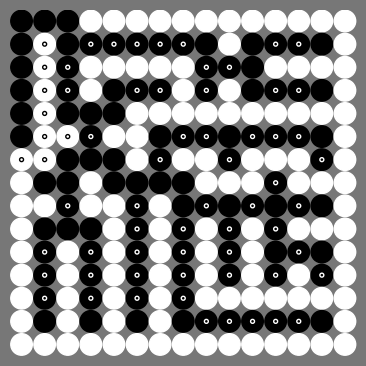

In [5]:
%%time
puzzle = np.loadtxt('data/yinyang02.txt', dtype=np.uint8)
cells, numbers, edges = solve_yinyang(puzzle)
plot_yinyang(puzzle, cells=cells);

更大的 25×25 盘面则要花相当长的时间。规模变大之后，编号与边的组合随之增加，求解时间增长很快。

status: OPTIMAL
CPU times: total: 4min 28s
Wall time: 14.8 s


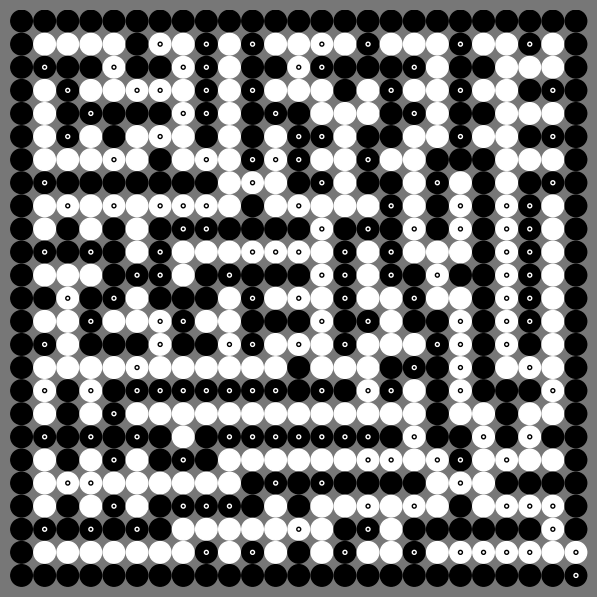

In [6]:
%%time
puzzle = np.loadtxt('data/yinyang03.txt', dtype=np.uint8)
cells, numbers, edges = solve_yinyang(puzzle)
plot_yinyang(puzzle, cells=cells);

## 验算

确认两种颜色是否各自连通，并确认是否出现了 2×2 方块，验算只检查结果，与建模方式无关。

In [7]:
def check_yinyang(puzzle, cells):
    h, w = puzzle.shape
    grid = np.array([[cells[r, c] for c in range(w)] for r in range(h)])

    # 3. 没有同色的 2×2
    for r in range(h - 1):
        for c in range(w - 1):
            quad = grid[r:r+2, c:c+2]
            if quad.min() == quad.max():
                return False, f"有同色的 2×2 {(r, c)}"

    # 1, 2. 每种颜色都连通
    for color, name in ((0, "白"), (1, "黑")):
        points = {(r, c) for r in range(h) for c in range(w) if grid[r, c] == color}
        if not points:
            continue
        start = next(iter(points))
        seen = {start}
        stack = [start]
        while stack:
            r, c = stack.pop()
            for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                nb = (r + dr, c + dc)
                if nb in points and nb not in seen:
                    seen.add(nb)
                    stack.append(nb)
        if seen != points:
            return False, f"{name}色分成了两块以上"

    return True, "两种颜色都连通，也没有 2×2"


print(check_yinyang(puzzle, cells))

(True, '两种颜色都连通，也没有 2×2')


## 小结

- 用颜色与遍历顺序两个变量，就可以表示同色的连通
- 相邻的同色格之间必定按其中一个方向的边相连，编号沿边的方向递增
- 把每格的入口限制为一条，从起点出发就能走到每一格，也就是连通
- 禁止 2×2 可以用四格的 OR 与它的否定的 OR 写出
- 比较式不适合作为条件，因此展开成 CNF，用 `add_bool_or` 给出
- 25×25 这样大的盘面需要相当的时间，也可以指定时间上限

出题网站上也有一些盘面只给了一种颜色的棋子，由于起点是按颜色分别选取的，这种情况下就要另行设计另一种颜色的起点，例如把它固定在某个已知的格上。